In [1]:
import sys
import time
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Allow imports from src/
sys.path.append('..')
from src.preprocess import load_data, build_preprocessor

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, confusion_matrix, classification_report

# Ensure results directories exist
os.makedirs('../results/figures', exist_ok=True)
os.makedirs('../models', exist_ok=True)

In [2]:
# 1. Load the shared stratified 80/20 split
X_train, X_val, y_train, y_val = load_data()
print("Data loaded:", X_train.shape, X_val.shape)

# 2. Build the tree pipeline
preprocessor = build_preprocessor("tree")
rf_baseline = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

pipeline_rf = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', rf_baseline)
])

Data loaded: (208480, 38) (52121, 38)


In [3]:
# 3. Train and measure time
start_time = time.time()
pipeline_rf.fit(X_train, y_train)
train_time = round(time.time() - start_time, 2)

# 4. Predict
y_train_pred = pipeline_rf.predict(X_train)
y_val_pred = pipeline_rf.predict(X_val)

# 5. Evaluate micro and macro F1
train_micro = round(f1_score(y_train, y_train_pred, average='micro'), 4)
val_micro = round(f1_score(y_val, y_val_pred, average='micro'), 4)
val_macro = round(f1_score(y_val, y_val_pred, average='macro'), 4)

print(f"Training Time: {train_time} seconds")
print(f"Train Micro-F1: {train_micro}")
print(f"Val Micro-F1:   {val_micro}")
print(f"Val Macro-F1:   {val_macro}")
print(f"Overfitting Gap: {round((train_micro - val_micro) * 100, 2)}%")

Training Time: 13.1 seconds
Train Micro-F1: 0.9868
Val Micro-F1:   0.723
Val Macro-F1:   0.6662
Overfitting Gap: 26.38%


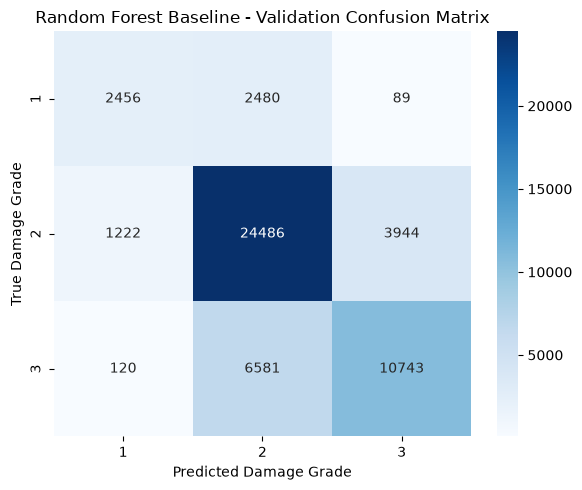

In [4]:
# 6. Plot and save confusion matrix
cm = confusion_matrix(y_val, y_val_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=[1, 2, 3], yticklabels=[1, 2, 3])
plt.title("Random Forest Baseline - Validation Confusion Matrix")
plt.xlabel("Predicted Damage Grade")
plt.ylabel("True Damage Grade")
plt.tight_layout()
plt.savefig('../results/figures/rf_baseline_confusion_matrix.png', dpi=300)
plt.show()

In [5]:
# 7. Append row to results/results.csv per project specification
results_path = '../results/results.csv'
new_row = pd.DataFrame([{
    'model': 'random_forest_baseline',
    'train_micro_f1': train_micro,
    'val_micro_f1': val_micro,
    'val_macro_f1': val_macro,
    'train_time_sec': train_time
}])

if os.path.exists(results_path):
    df_results = pd.read_csv(results_path)
    df_results = pd.concat([df_results, new_row], ignore_index=True)
else:
    df_results = new_row

df_results.to_csv(results_path, index=False)
print("Updated results/results.csv:")
print(pd.read_csv(results_path))

Updated results/results.csv:
                    model  train_micro_f1  val_micro_f1  val_macro_f1  \
0  random_forest_baseline          0.9868         0.723        0.6662   
1  random_forest_baseline          0.9868         0.723        0.6662   

   train_time_sec  
0           12.35  
1           13.10  


In [6]:
# Clean up duplicate baseline row
df_res = pd.read_csv('../results/results.csv').drop_duplicates(subset=['model'], keep='last')
df_res.to_csv('../results/results.csv', index=False)
print("Current clean results:")
print(df_res)

Current clean results:
                    model  train_micro_f1  val_micro_f1  val_macro_f1  \
1  random_forest_baseline          0.9868         0.723        0.6662   

   train_time_sec  
1            13.1  


In [7]:
from sklearn.model_selection import RandomizedSearchCV

# Define parameter distributions from Task 2 instructions
param_dist = {
    'classifier__max_depth': [10, 20, 30, None],
    'classifier__min_samples_leaf': [1, 5, 10, 20],
    'classifier__n_estimators': [100, 200],
    'classifier__max_features': ['sqrt', 0.5]
}

# 3-fold CV for speed, searching 10 random combinations
rf_search = RandomizedSearchCV(
    pipeline_rf,
    param_distributions=param_dist,
    n_iter=10,
    scoring='f1_micro',
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

start_time = time.time()
rf_search.fit(X_train, y_train)
tune_time = round(time.time() - start_time, 2)

best_rf = rf_search.best_estimator_
print(f"Tuning finished in {tune_time}s")
print("Best parameters:", rf_search.best_params_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Tuning finished in 592.97s
Best parameters: {'classifier__n_estimators': 100, 'classifier__min_samples_leaf': 5, 'classifier__max_features': 0.5, 'classifier__max_depth': None}


In [11]:
y_train_tuned = best_rf.predict(X_train)
y_val_tuned = best_rf.predict(X_val)

train_micro_tuned = round(f1_score(y_train, y_train_pred := y_train_tuned, average='micro'), 4)
val_micro_tuned = round(f1_score(y_val, y_val_tuned, average='micro'), 4)
val_macro_tuned = round(f1_score(y_val, y_val_tuned, average='macro'), 4)

tuned_gap = round((train_micro_tuned - val_micro_tuned) * 100, 2)

print(f"--- Tuned Random Forest ---")
print(f"Train Micro-F1: {train_micro_tuned}")
print(f"Val Micro-F1:   {val_micro_tuned}")
print(f"Val Macro-F1:   {val_macro_tuned}")
print(f"New Overfitting Gap: {tuned_gap}% (Down from 26.38%!)")

# Save tuned model
joblib.dump(best_rf, '../models/rf.joblib')

# Append to results.csv
new_row = pd.DataFrame([{
    'model': 'random_forest_tuned',
    'train_micro_f1': train_micro_tuned,
    'val_micro_f1': val_micro_tuned,
    'val_macro_f1': val_macro_tuned,
    'train_time_sec': tune_time
}])
df_res = pd.concat([pd.read_csv('../results/results.csv'), new_row], ignore_index=True)
df_res.to_csv('../results/results.csv', index=False)

--- Tuned Random Forest ---
Train Micro-F1: 0.8362
Val Micro-F1:   0.7428
Val Macro-F1:   0.6835
New Overfitting Gap: 9.34% (Down from 26.38%!)


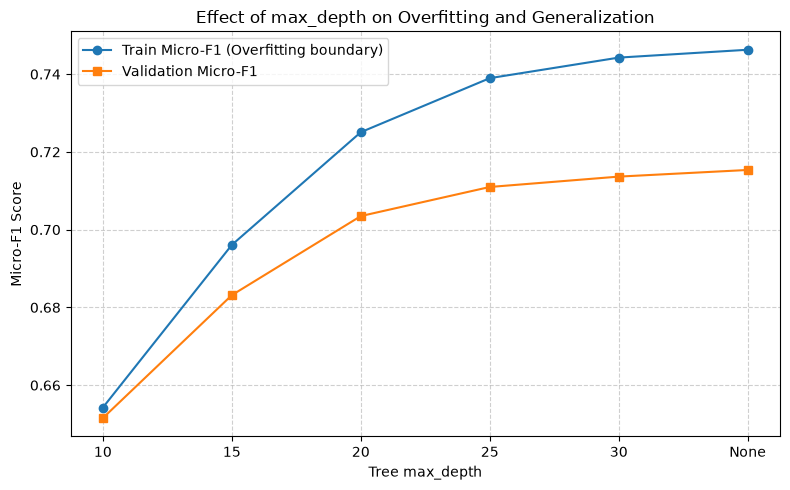

In [12]:
depths = [10, 15, 20, 25, 30]
depth_labels = [str(d) for d in depths] + ['None']
train_f1s = []
val_f1s = []

for d in depths + [None]:
    temp_rf = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(max_depth=d, min_samples_leaf=10, n_estimators=100, random_state=42, n_jobs=-1))
    ])
    temp_rf.fit(X_train, y_train)
    train_f1s.append(f1_score(y_train, temp_rf.predict(X_train), average='micro'))
    val_f1s.append(f1_score(y_val, temp_rf.predict(X_val), average='micro'))

plt.figure(figsize=(8, 5))
plt.plot(depth_labels, train_f1s, marker='o', label='Train Micro-F1 (Overfitting boundary)')
plt.plot(depth_labels, val_f1s, marker='s', label='Validation Micro-F1')
plt.title("Effect of max_depth on Overfitting and Generalization")
plt.xlabel("Tree max_depth")
plt.ylabel("Micro-F1 Score")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('../results/figures/rf_overfitting_depth_curve.png', dpi=300)
plt.show()

In [13]:
# Extract best classifier params and add balanced class weights
best_params_clean = {k.replace('classifier__', ''): v for k, v in rf_search.best_params_.items()}
best_params_clean['class_weight'] = 'balanced'
best_params_clean['random_state'] = 42
best_params_clean['n_jobs'] = -1

pipeline_rf_balanced = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(**best_params_clean))
])

start_time = time.time()
pipeline_rf_balanced.fit(X_train, y_train)
bal_time = round(time.time() - start_time, 2)

y_train_bal = pipeline_rf_balanced.predict(X_train)
y_val_bal = pipeline_rf_balanced.predict(X_val)

train_micro_bal = round(f1_score(y_train, y_train_bal, average='micro'), 4)
val_micro_bal = round(f1_score(y_val, y_val_bal, average='micro'), 4)
val_macro_bal = round(f1_score(y_val, y_val_bal, average='macro'), 4)

print("=== Classification Report (Before Balanced Weights) ===")
print(classification_report(y_val, y_val_tuned))

print("=== Classification Report (After Balanced Weights) ===")
print(classification_report(y_val, y_val_bal))

# Append random_forest_balanced to results.csv
new_row = pd.DataFrame([{
    'model': 'random_forest_balanced',
    'train_micro_f1': train_micro_bal,
    'val_micro_f1': val_micro_bal,
    'val_macro_f1': val_macro_bal,
    'train_time_sec': bal_time
}])
df_res = pd.concat([pd.read_csv('../results/results.csv'), new_row], ignore_index=True)
df_res.to_csv('../results/results.csv', index=False)
print("Updated results/results.csv:")
print(pd.read_csv('../results/results.csv'))

=== Classification Report (Before Balanced Weights) ===
              precision    recall  f1-score   support

           1       0.68      0.49      0.57      5025
           2       0.74      0.85      0.79     29652
           3       0.77      0.63      0.69     17444

    accuracy                           0.74     52121
   macro avg       0.73      0.66      0.68     52121
weighted avg       0.74      0.74      0.74     52121

=== Classification Report (After Balanced Weights) ===
              precision    recall  f1-score   support

           1       0.47      0.81      0.59      5025
           2       0.79      0.67      0.73     29652
           3       0.69      0.73      0.71     17444

    accuracy                           0.70     52121
   macro avg       0.65      0.74      0.68     52121
weighted avg       0.73      0.70      0.71     52121

Updated results/results.csv:
                    model  train_micro_f1  val_micro_f1  val_macro_f1  \
0  random_forest_baseline